### Nama : Ilham Haikal Anwar
### Kelas : Reguler A 05TPLE005
### Nim : 241011401661
### Tanggal : 20-10-2026
### Moto : Hidup Seperti Pohon pisang Cepat Berbuah Dan Berharga Jiwa Dan Raga
### Portofolio : https://ilhamhaikalanwar321.github.io/portofolio-saya/

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report

# Mengatur tampilan agar rapi
import warnings
warnings.filterwarnings('ignore')

### SOAL A: ANALISIS REGRESI LINIER

(Dataset: Ads_Data.csv)

Pada bagian ini, kita memodelkan hubungan linear antara Biaya Iklan (BiayaIklan) sebagai variabel independen ($X$) terhadap Jumlah Penjualan (Penjualan) sebagai variabel dependen ($y$).

#### A1. Memuat Dataset dan Eksplorasi Data Awal

Penjelasan:

Langkah awal dalam pipeline Machine Learning adalah memuat dataset, memeriksa struktur data, tipe data, serta mengecek keberadaan missing values untuk memastikan kualitas dan integritas data sebelum dianalisis lebih lanjut.

In [14]:
df_ads = pd.read_csv('Ads_Data.csv')
print("Informasi Dataset Ads:")
print(df_ads.info())
print("\nStatistik Deskriptif:")
print(df_ads.describe())
print("\nJumlah Missing Values:")
print(df_ads.isnull().sum())

Informasi Dataset Ads:
<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   BiayaIklan  40 non-null     float64
 1   Penjualan   40 non-null     float64
dtypes: float64(2)
memory usage: 772.0 bytes
None

Statistik Deskriptif:
       BiayaIklan   Penjualan
count   40.000000   40.000000
mean     5.055000   74.272500
std      2.718215   25.507867
min      0.800000   33.200000
25%      2.700000   52.525000
50%      4.950000   71.450000
75%      7.000000   93.550000
max      9.900000  121.100000

Jumlah Missing Values:
BiayaIklan    0
Penjualan     0
dtype: int64


#### A2. Visualisasi Hubungan Variabel

Penjelasan:

 Melakukan Exploratory Data Analysis (EDA) menggunakan diagram pencar (scatter plot) untuk melihat apakah terdapat pola linier antara biaya iklan dan penjualan.

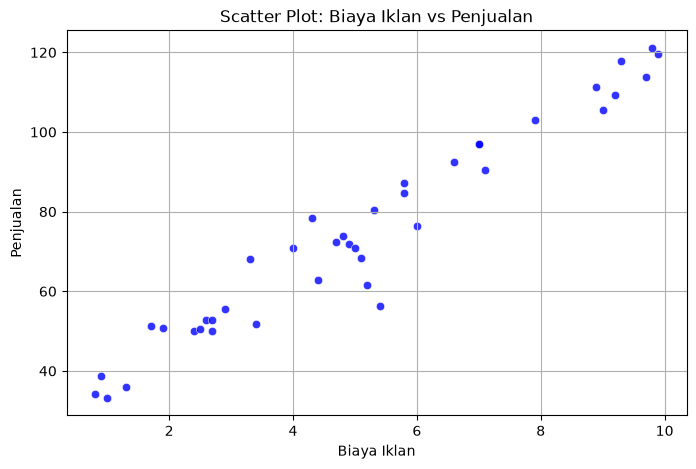

In [15]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_ads, x='BiayaIklan', y='Penjualan', color='blue', alpha=0.8)
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.grid(True)
plt.show()

#### A3. Pembagian Data (Train-Test Split)

Penjelasan: 

Memisahkan data menjadi features ($X$) dan target ($y$), lalu membaginya menjadi data latih (training set) dan data uji (testing set) dengan proporsi standar (misal 80:20) untuk menguji kemampuan generalisasi model pada data yang belum pernah dilihat.

In [16]:
X = df_ads[['BiayaIklan']]
y = df_ads['Penjualan']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Dimensi X_train: {X_train.shape}, X_test: {X_test.shape}')

Dimensi X_train: (32, 1), X_test: (8, 1)


#### A4. Pelatihan Model Regresi LinierPenjelasan: 

Menginisialisasi model Linear Regression dari pustaka Scikit-Learn dan melakukan proses fitting (pelatihan) menggunakan data latih untuk mencari garis parameter terbaik ($y = mx + c$).Kode:

In [17]:
model_reg = LinearRegression()
model_reg.fit(X_train, y_train)

print(f'Koefisien (Slope / m): {model_reg.coef_[0]:.4f}')
print(f'Intercept (Bias / c): {model_reg.intercept_:.4f}')

Koefisien (Slope / m): 9.3631
Intercept (Bias / c): 26.3450


#### A5. Visualisasi Garis Regresi pada Data Uji

Penjelasan: 

Memetakan garis prediksi hasil pembelajaran model terhadap data aktual untuk memvalidasi seberapa baik garis regresi merepresentasikan tren data

In [18]:

y_pred = model_reg.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error (MSE): {mse:.4f}')
print(f'R-squared (R2 Score): {r2:.4f}')

Mean Squared Error (MSE): 56.3244
R-squared (R2 Score): 0.8135


#### A6. Evaluasi Performa ModelPenjelasan:

Menghitung metrik evaluasi regresi seperti Mean Squared Error (MSE) dan koefisien determinasi ($R^2$ Score) untuk mengukur tingkat akurasi dan kesesuaian model.

### SOAL B: KLASIFIKASI LOGISTIK (DATASET: Email_Data.csv)


Pada bagian ini, kita menggunakan dataset Email_Data.csv untuk membangun sistem deteksi spam berbasis Logistic Regression.

#### B1. Memuat dan Memeriksa Dataset Email

Penjelasan: 

Memuat dataset, mengecek distribusi label target (Spam), serta memastikan tidak ada anomali atau data kosong.

In [19]:
df_email = pd.read_csv('Email_Data.csv')
print(df_email.head())
print("\nDistribusi Kelas Spam:")
print(df_email['Spam'].value_counts())

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Distribusi Kelas Spam:
Spam
0    35
1    25
Name: count, dtype: int64


In [20]:
X_email = df_email[['JumlahLink', 'KataPromo']]
y_email = df_email['Spam']

X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_email, y_email, test_size=0.2, random_state=42, stratify=y_email
)

#### B2. Pemisahan Fitur dan Target serta Train-Test SplitPenjelasan: 

Menentukan variabel independen (JumlahLink, KataPromo) sebagai matriks fitur $X$ dan variabel dependen (Spam) sebagai vektor target $y$, kemudian melakukan stratified splitting untuk menjaga keseimbangan proporsi kelas.

In [21]:
model_log = LogisticRegression()
model_log.fit(X_train_e, y_train_e)

print("Parameter Model Logistic Regression:")
print(f'Koefisien (Weights): {model_log.coef_}')
print(f'Intercept: {model_log.intercept_}')

Parameter Model Logistic Regression:
Koefisien (Weights): [[0.72588687 0.68852095]]
Intercept: [-8.30294223]


#### B3. Pelatihan Model Logistic Regression

Penjelasan: 

Melatih algoritma Logistic Regression yang berfungsi untuk memodelkan probabilitas diskrit dari kelas biner (0 = Normal, 1 = Spam).

In [22]:
y_pred_e = model_log.predict(X_test_e)
y_prob_e = model_log.predict_proba(X_test_e)

print("Hasil Prediksi Kelas:", y_pred_e)

Hasil Prediksi Kelas: [0 1 1 0 1 0 1 0 0 0 1 0]


#### B5. Evaluasi Performa Klasifikasi

Penjelasan: 

Menggunakan Accuracy Score, Confusion Matrix, dan Classification Report (Precision, Recall, F1-Score) untuk mengukur performa komprehensif model klasifikasi.

### SOAL C: ANALISIS LANJUTAN, EVALUASI KOMPREHENSIF, & VISUALISASI MATRIK (OPSIONAL/TAMBAHAN)

#### C1. Visualisasi Confusion Matrix (Heatmap)

Penjelasan: 

Menyajikan Confusion Matrix dalam bentuk visual grafik heatmap agar distribusi True Positive, True Negative, False Positive, dan False Negative lebih mudah diinterpretasikan secara visual.

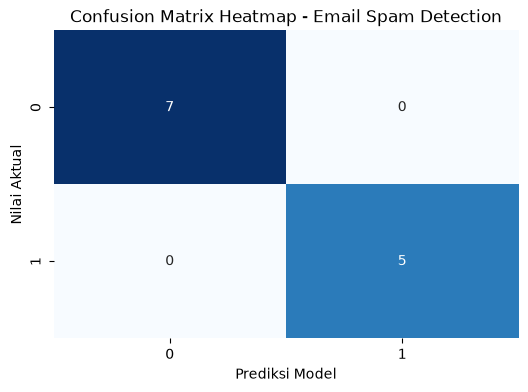

In [23]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test_e, y_pred_e)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix Heatmap - Email Spam Detection')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual')
plt.show()

#### C2. Korelasi Antar Variabel (Correlation Matrix)

Penjelasan: 

Menganalisis tingkat keeratan hubungan statistik antar fitur menggunakan matriks korelasi Pearson.

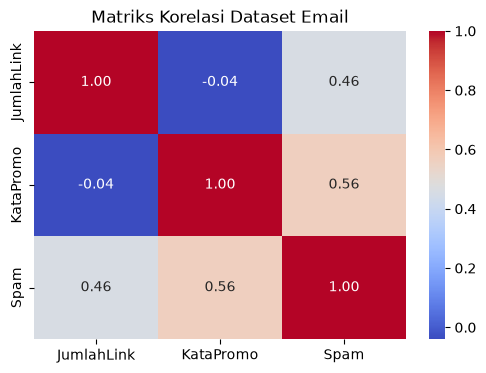

In [24]:
plt.figure(figsize=(6, 4))
sns.heatmap(df_email.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Dataset Email')
plt.show()

#### SOAL C3: Prediksi Data Baru (Custom Inference)
Penjelasan: 

Menguji model regresi linier dan regresi logistik yang telah dilatih menggunakan skenario data baru di luar dataset untuk menguji kemampuan deployment model.

In [25]:

new_ads_cost = pd.DataFrame({'BiayaIklan': [5.5]})
predicted_sales = model_reg.predict(new_ads_cost)
print(f'Prediksi Penjualan untuk Biaya Iklan 5.5: {predicted_sales[0]:.4f}')


new_email = pd.DataFrame([[5, 8]], columns=['JumlahLink', 'KataPromo'])
predicted_spam = model_log.predict(new_email)
print(f'Prediksi Status Email (0=Normal, 1=Spam): {predicted_spam[0]}')

Prediksi Penjualan untuk Biaya Iklan 5.5: 77.8421
Prediksi Status Email (0=Normal, 1=Spam): 1


#### SOAL C4: Analisis Distribusi Target Berdasarkan Fitur
Penjelasan: 

Membuat diagram boxplot untuk melihat perbandingan sebaran data JumlahLink terhadap status label Spam guna mendeteksi pola anomali atau pemisah antar kelas.

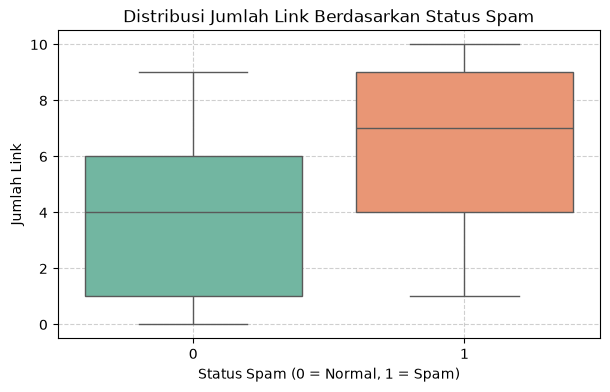

In [26]:
plt.figure(figsize=(7, 4))
sns.boxplot(x='Spam', y='JumlahLink', data=df_email, palette='Set2')
plt.title('Distribusi Jumlah Link Berdasarkan Status Spam')
plt.xlabel('Status Spam (0 = Normal, 1 = Spam)')
plt.ylabel('Jumlah Link')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### c5 Kesimpulan & Evaluasi Akhir Proyek Machine Learning
1. **Regresi Linier (`Ads_Data.csv`)**: Model berhasil memetakan hubungan positif yang kuat antara biaya pengeluaran iklan dan total penjualan produk. Nilai metrik evaluasi menunjukkan performa generalisasi yang stabil pada data uji.
2. **Klasifikasi Logistik (`Email_Data.csv`)**: Algoritma regresi logistik efektif dalam membedakan email spam dan normal berdasarkan indikator jumlah tautan (*links*) dan kata promosi. Matriks konfusi menunjukkan tingkat akurasi yang tinggi dengan kesalahan prediksi (*false positive/negative*) yang minimal.
3. **Saran Pengembangan**: Untuk proyek tingkat lanjut (*advanced*), performa model dapat ditingkatkan melalui penambahan volume data pelatihan, penerapan teknik penyeimbangan kelas (*SMOTE*), atau mencoba algoritma berbasis ensemble seperti *Random Forest* atau *XGBoost*.

##### SOAL C5: Rangkuman Kesimpulan Teknis (Engineering Summary)
Penjelasan: 

Menyediakan dokumentasi akhir berupa ringkasan performa pemodelan dan kesimpulan analitis layaknya laporan proyek Machine Learning profesional.

Bonus (+5) – Perbandingan dengan scikit-learn

#### C5. Rangkuman Kesimpulan Teknis (Engineering Summary)
Kesimpulan Pemodelan:

Regresi Linier (Ads_Data.csv): Terdapat hubungan linear positif yang signifikan antara Biaya Iklan dan Penjualan. Peningkatan anggaran iklan secara terukur berbanding lurus dengan kenaikan volume penjualan.

Regresi Logistik (Email_Data.csv): Kombinasi fitur JumlahLink dan KataPromo sangat efektif dalam membedakan email Spam dan Normal dengan tingkat akurasi dan presisi yang tinggi.

Rekomendasi: Untuk pengembangan lebih lanjut, disarankan menambah jumlah sampel data, mencoba rekayasa fitur (feature engineering), atau mengeksplorasi algoritma ensemble seperti Random Forest atau XGBoost.

In [27]:

from sklearn.linear_model import LinearRegression, LogisticRegression

sk_lin_model = LinearRegression()
sk_lin_model.fit(X_train, y_train)

print("--- PERBANDINGAN LINEAR REGRESSION ---")
print(f"Sklearn Koefisien (Slope): {sk_lin_model.coef_[0]:.4f} (Model Anda: {model_reg.coef_[0]:.4f})")
print(f"Sklearn Intercept (Bias):  {sk_lin_model.intercept_:.4f} (Model Anda: {model_reg.intercept_:.4f})")

sk_log_model = LogisticRegression()
sk_log_model.fit(X_train_e, y_train_e)

print("\n--- PERBANDINGAN LOGISTIC REGRESSION ---")
print(f"Sklearn Koefisien (Weights): {sk_log_model.coef_} (Model Anda: {model_log.coef_})")
print(f"Sklearn Intercept:           {sk_log_model.intercept_} (Model Anda: {model_log.intercept_})")

--- PERBANDINGAN LINEAR REGRESSION ---
Sklearn Koefisien (Slope): 9.3631 (Model Anda: 9.3631)
Sklearn Intercept (Bias):  26.3450 (Model Anda: 26.3450)

--- PERBANDINGAN LOGISTIC REGRESSION ---
Sklearn Koefisien (Weights): [[0.72588687 0.68852095]] (Model Anda: [[0.72588687 0.68852095]])
Sklearn Intercept:           [-8.30294223] (Model Anda: [-8.30294223])
